# Data Mining Lab Assignment 2: Book Recommender System using a Medallion Data Lake

| Field | Details |
| :--- | :--- |
| **Student Name** | Rahul Bharadwaz |
| **Roll Number** | LCI2023019 |
| **Program** | B.Tech (7th Semester), IIIT Lucknow |
| **Architecture** | Medallion Data Lake (`Bronze` $\rightarrow$ `Silver` $\rightarrow$ `Gold`) |
| **Dataset** | Book-Crossing (`BX-Users.csv`, `BX-Books.csv`, `BX-Book-Ratings.csv`) |
| **Model** | Item-Based Collaborative Filtering (`NearestNeighbors`, Cosine Similarity) |

---

### Pipeline Overview
1. **Bronze Layer (Raw Ingestion):** Land untouched Book-Crossing CSV tables into columnar Parquet files (`bronze/`) with an `ingestion_timestamp` audit column.
2. **Bronze Exploratory Data Analysis (EDA):** Audit schema, missingness, rating semantics (`0` implicit vs `1–10` explicit), impossible `Age` / `Year-Of-Publication` values, long-tail user/book distributions, and interaction matrix sparsity.
3. **Silver Layer (Cleaned & Conformed):** Deduplicate records, isolate explicit ratings (`1–10`), sanitize ages and publication years, parse `Location` into `(city, state, country)`, normalize text metadata, drop image URLs, enforce referential integrity, and filter cold-start tail (`>= 10` ratings).
4. **Gold Layer (Serving & Feature Store):** Build and persist a CSR sparse rating matrix (`gold/rating_matrix.npz`), deterministic user/book index mappings, a compact `book_lookup` table, and user/book aggregate statistics.
5. **Item-Based Collaborative Filtering:** Fit `NearestNeighbors(metric='cosine', algorithm='brute')` on the `(n_books, n_users)` sparse matrix and expose `get_similar_books()` and `recommend()`.
6. **Demo & Sanity Check:** Validate item similarity on a well-known book and inspect top-10 personalized recommendations for three diverse Gold users.

## Step 1: Set Up Data Lake & Bronze Layer

In the **Bronze layer**, data must remain an **exact, immutable snapshot** of the source system. We:
1. Ensure required dependencies (`pandas`, `numpy`, `pyarrow`, `scipy`, `scikit-learn`, `requests`) and plotting helpers are available (Colab-ready).
2. Create the Medallion directory structure (`bronze/`, `silver/`, `gold/`).
3. Download and extract the Book-Crossing dataset archive.
4. Load all three CSVs with exact raw parsing flags (`sep=';'`, `encoding='latin-1'`, `on_bad_lines='skip'`, `low_memory=False`), append an `ingestion_timestamp`, and persist untouched to `bronze/*.parquet`.

In [1]:
import importlib.util
import subprocess
import sys

# Ensure all required packages are installed (seamless for Google Colab & fresh environments)
REQUIRED_PACKAGES = {
    "pandas": "pandas",
    "numpy": "numpy",
    "pyarrow": "pyarrow",
    "scipy": "scipy",
    "sklearn": "scikit-learn",
    "requests": "requests",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
}

missing = [pkg for mod, pkg in REQUIRED_PACKAGES.items() if importlib.util.find_spec(mod) is None]
if missing:
    print(f"Installing missing packages: {missing}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import html
import re
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import requests
import scipy.sparse as sp
import seaborn as sns
from IPython.display import display
from sklearn.neighbors import NearestNeighbors

# Plotting configuration for clean, readable inline figures
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
})

# Keep SettingWithCopyWarning active so our code proves clean copy/loc hygiene
pd.options.mode.chained_assignment = "warn"

# Create Medallion Data Lake directories
BRONZE_DIR = Path("bronze")
SILVER_DIR = Path("silver")
GOLD_DIR = Path("gold")
RAW_DIR = Path("raw_data")

for d in (BRONZE_DIR, SILVER_DIR, GOLD_DIR, RAW_DIR):
    d.mkdir(parents=True, exist_ok=True)

print("Environment ready.")
print(f"pandas={pd.__version__}, numpy={np.__version__}, pyarrow={pa.__version__}, scipy={sp.__name__}")
print("Directories created:", [str(d) for d in (BRONZE_DIR, SILVER_DIR, GOLD_DIR)])

C:\Users\rahul\AppData\Roaming\Python\Python313\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.3.0) or chardet (7.4.3)/charset_normalizer (3.4.1) doesn't match a supported version!
  warnings.warn(


Environment ready.
pandas=2.2.3, numpy=2.2.3, pyarrow=25.0.1, scipy=scipy.sparse
Directories created: ['bronze', 'silver', 'gold']


In [2]:
DATA_URL = "https://cdn.freecodecamp.org/project-data/books/book-crossings.zip"
ZIP_PATH = RAW_DIR / "book-crossings.zip"

if not ZIP_PATH.exists():
    print(f"Downloading dataset from {DATA_URL} ...")
    with requests.get(DATA_URL, stream=True, timeout=120) as resp:
        resp.raise_for_status()
        with open(ZIP_PATH, "wb") as f:
            for chunk in resp.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    f.write(chunk)
    print(f"Downloaded {ZIP_PATH.stat().st_size / (1024 ** 2):.2f} MB to {ZIP_PATH}")
else:
    print(f"Using cached archive at {ZIP_PATH} ({ZIP_PATH.stat().st_size / (1024 ** 2):.2f} MB)")

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    zf.extractall(RAW_DIR)

def find_extracted_csv(filename: str) -> Path:
    matches = list(RAW_DIR.rglob(filename))
    if not matches:
        raise FileNotFoundError(f"Could not find {filename} inside {RAW_DIR}")
    return matches[0]

users_csv = find_extracted_csv("BX-Users.csv")
books_csv = find_extracted_csv("BX-Books.csv")
ratings_csv = find_extracted_csv("BX-Book-Ratings.csv")

for path in (users_csv, books_csv, ratings_csv):
    print(f"Found {path.name}: {path.stat().st_size / (1024 ** 2):.2f} MB ({path})")

Using cached archive at raw_data\book-crossings.zip (24.88 MB)


Found BX-Users.csv: 11.72 MB (raw_data\BX-Users.csv)
Found BX-Books.csv: 74.18 MB (raw_data\BX-Books.csv)
Found BX-Book-Ratings.csv: 29.26 MB (raw_data\BX-Book-Ratings.csv)


In [3]:
# Load raw CSVs untouched with required parameters
csv_kwargs = dict(sep=";", encoding="latin-1", on_bad_lines="skip", low_memory=False)

users_raw = pd.read_csv(users_csv, **csv_kwargs)
books_raw = pd.read_csv(books_csv, **csv_kwargs)
ratings_raw = pd.read_csv(ratings_csv, **csv_kwargs)

# Append ingestion audit timestamp without modifying raw values
ingestion_ts = pd.Timestamp.now()
users_raw["ingestion_timestamp"] = ingestion_ts
books_raw["ingestion_timestamp"] = ingestion_ts
ratings_raw["ingestion_timestamp"] = ingestion_ts

# Persist untouched Bronze tables as Parquet
users_raw.to_parquet(BRONZE_DIR / "users.parquet", index=False)
books_raw.to_parquet(BRONZE_DIR / "books.parquet", index=False)
ratings_raw.to_parquet(BRONZE_DIR / "ratings.parquet", index=False)

print(f"Bronze layer saved at ingestion_timestamp={ingestion_ts}")
for name, df in [("users", users_raw), ("books", books_raw), ("ratings", ratings_raw)]:
    pq_size_mb = (BRONZE_DIR / f"{name}.parquet").stat().st_size / (1024 ** 2)
    print(f"  bronze/{name}.parquet -> shape={df.shape}, size={pq_size_mb:.2f} MB")

Bronze layer saved at ingestion_timestamp=2026-11-28 22:08:57.247630
  bronze/users.parquet -> shape=(278858, 4), size=4.15 MB
  bronze/books.parquet -> shape=(271360, 9), size=20.65 MB
  bronze/ratings.parquet -> shape=(1149780, 4), size=9.36 MB


## Step 2: Explore the Bronze Data (EDA)

Before designing any Silver cleaning rules, we read the raw tables back from `bronze/*.parquet` and inspect:
- **(a)** Table dimensions, column dtypes, missing-value counts, and duplicate rows.
- **(b)** Rating distribution (implicit `0` vs explicit `1–10`).
- **(c)** Domain validity of user `Age` and book `Year-Of-Publication`.
- **(d)** Per-user and per-book rating activity (quantiles and cold-start tail percentages).
- **(e)** Interaction matrix density, overall sparsity, and referential overlap.

In [4]:
# Read Bronze Parquet tables back from disk
users_bronze = pd.read_parquet(BRONZE_DIR / "users.parquet")
books_bronze = pd.read_parquet(BRONZE_DIR / "books.parquet")
ratings_bronze = pd.read_parquet(BRONZE_DIR / "ratings.parquet")

print("Loaded Bronze Parquet tables successfully.")

Loaded Bronze Parquet tables successfully.


In [5]:
# 2(a) Shape, data types, missing-value counts, and duplicate rows
for name, df in [("users_bronze", users_bronze), ("books_bronze", books_bronze), ("ratings_bronze", ratings_bronze)]:
    print("=" * 72)
    print(f"Table: {name} | Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
    exact_dups = df.duplicated().sum()
    data_cols = [c for c in df.columns if c != "ingestion_timestamp"]
    payload_dups = df.duplicated(subset=data_cols).sum()
    print(f"Exact duplicate rows: {exact_dups:,} | Payload duplicate rows (excl. timestamp): {payload_dups:,}")
    schema_df = pd.DataFrame({
        "Dtype": df.dtypes.astype(str),
        "Non-Null": df.notna().sum(),
        "Missing": df.isna().sum(),
        "Missing (%)": (df.isna().mean() * 100).round(2),
    })
    display(schema_df)

Table: users_bronze | Shape: 278,858 rows x 4 columns
Exact duplicate rows: 0 | Payload duplicate rows (excl. timestamp): 0


,Dtype,Non-Null,Missing,Missing (%)
User-ID,int64,278858,0,0.00
Location,object,278858,0,0.00
Age,float64,168096,110762,39.72
ingestion_timestamp,datetime64[us],278858,0,0.00


Table: books_bronze | Shape: 271,360 rows x 9 columns


Exact duplicate rows: 0 | Payload duplicate rows (excl. timestamp): 0


,Dtype,Non-Null,Missing,Missing (%)
ISBN,object,271360,0,0.0
Book-Title,object,271360,0,0.0
Book-Author,object,271358,2,0.0
Year-Of-Publication,object,271360,0,0.0
Publisher,object,271358,2,0.0
Image-URL-S,object,271360,0,0.0
Image-URL-M,object,271360,0,0.0
Image-URL-L,object,271357,3,0.0
ingestion_timestamp,datetime64[us],271360,0,0.0


Table: ratings_bronze | Shape: 1,149,780 rows x 4 columns


Exact duplicate rows: 0 | Payload duplicate rows (excl. timestamp): 0


,Dtype,Non-Null,Missing,Missing (%)
User-ID,int64,1149780,0,0.0
ISBN,object,1149780,0,0.0
Book-Rating,int64,1149780,0,0.0
ingestion_timestamp,datetime64[us],1149780,0,0.0


**Finding:** Bronze holds `278,858` users (`Age` missing in `110,762` rows / `39.72%`), `271,360` books (`Year-Of-Publication` stored as `object` due to string shifts; `2` missing authors/publishers, `3` missing `Image-URL-L`), and `1,149,780` ratings with `0` missing values and `0` exact duplicates. | **Silver Action:** Enforce primary-key deduplication, impute missing `Age` with median valid age, coerce `Year-Of-Publication` to numeric, fill missing text metadata with `'Unknown'`, and drop unused `Image-URL-*` columns.

Total ratings in Bronze        : 1,149,780
Implicit ratings (0)           : 716,109 (62.28%)
Explicit ratings (1-10)        : 433,671 (37.72%)
Out-of-range ratings           : 0
Explicit (1-10) summary stats  : mean=7.601, median=8.0, std=1.844


,Count,Percentage (%)
Book-Rating,,
0,716109,62.28
1,1770,0.15
2,2759,0.24
3,5996,0.52
4,8904,0.77
5,50974,4.43
6,36924,3.21
7,76457,6.65
8,103736,9.02


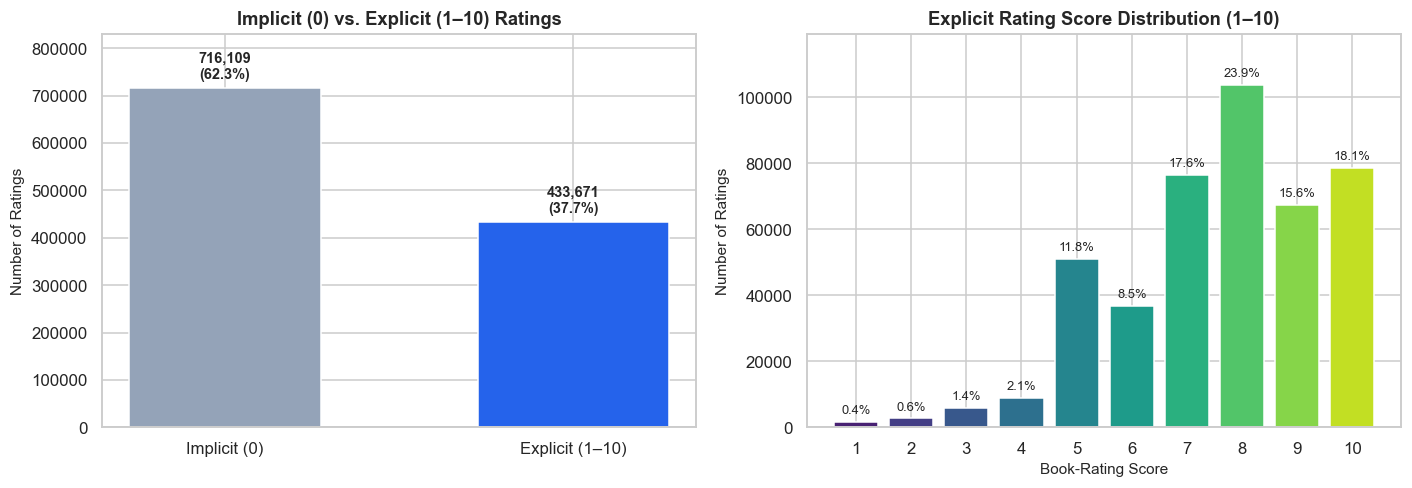

In [6]:
# 2(b) Distribution of Book-Rating (0 vs 1-10)
total_ratings = len(ratings_bronze)
rating_counts = ratings_bronze["Book-Rating"].value_counts().sort_index()
rating_pcts = (rating_counts / total_ratings) * 100

implicit_count = int((ratings_bronze["Book-Rating"] == 0).sum())
explicit_mask = (ratings_bronze["Book-Rating"] >= 1) & (ratings_bronze["Book-Rating"] <= 10)
explicit_count = int(explicit_mask.sum())
out_of_range_count = int((~explicit_mask & (ratings_bronze["Book-Rating"] != 0)).sum())

implicit_pct = (implicit_count / total_ratings) * 100
explicit_pct = (explicit_count / total_ratings) * 100
explicit_ratings = ratings_bronze.loc[explicit_mask, "Book-Rating"]

print(f"Total ratings in Bronze        : {total_ratings:,}")
print(f"Implicit ratings (0)           : {implicit_count:,} ({implicit_pct:.2f}%)")
print(f"Explicit ratings (1-10)        : {explicit_count:,} ({explicit_pct:.2f}%)")
print(f"Out-of-range ratings           : {out_of_range_count:,}")
print(
    f"Explicit (1-10) summary stats  : mean={explicit_ratings.mean():.3f}, "
    f"median={explicit_ratings.median():.1f}, std={explicit_ratings.std():.3f}"
)

dist_table = pd.DataFrame({
    "Count": rating_counts,
    "Percentage (%)": rating_pcts.round(2),
})
display(dist_table)

# Visualization: Implicit vs Explicit split & Explicit 1-10 breakdown
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

split_labels = ["Implicit (0)", "Explicit (1–10)"]
split_vals = [implicit_count, explicit_count]
bars_left = axes[0].bar(split_labels, split_vals, color=["#94a3b8", "#2563eb"], width=0.55)
axes[0].set_title("Implicit (0) vs. Explicit (1–10) Ratings")
axes[0].set_ylabel("Number of Ratings")
axes[0].set_ylim(0, max(split_vals) * 1.16)
for bar, cnt in zip(bars_left, split_vals):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(split_vals) * 0.02,
        f"{cnt:,}\n({cnt / total_ratings * 100:.1f}%)",
        ha="center", va="bottom", fontsize=9.5, fontweight="bold"
    )

exp_counts = explicit_ratings.value_counts().sort_index()
exp_palette = sns.color_palette("viridis", n_colors=len(exp_counts))
bars_right = axes[1].bar(exp_counts.index.astype(str), exp_counts.values, color=exp_palette)
axes[1].set_title("Explicit Rating Score Distribution (1–10)")
axes[1].set_xlabel("Book-Rating Score")
axes[1].set_ylabel("Number of Ratings")
axes[1].set_ylim(0, exp_counts.max() * 1.15)
for bar, cnt in zip(bars_right, exp_counts.values):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + exp_counts.max() * 0.015,
        f"{cnt / explicit_count * 100:.1f}%",
        ha="center", va="bottom", fontsize=8.5
    )

plt.tight_layout()
plt.show()

**Finding:** Of `1,149,780` ratings, `716,109` (`62.28%`) are implicit `0`s while `433,671` (`37.72%`) are explicit `1–10` scores (mean `7.601`, median `8.0`, mode `8` at `103,736`). | **Silver Action:** Drop all `0` ratings so cosine similarities reflect true explicit preference intensity (`1–10`).

--- User Age Audit ---
Total users                    : 278,858
Missing (NaN) Age              : 110,762 (39.72%)
Non-numeric Age                : 0
Impossible Age (< 5)           : 882
Impossible Age (> 100)         : 366
Total impossible (<5 or >100)  : 1,248 (0.45%)
Valid Age (5-100) count        : 166,848 (59.83%)
Valid Age summary:


,count,mean,std,min,5%,25%,50%,75%,95%,max
Age,166848.0,34.746638,13.633051,5.0,16.0,24.0,32.0,44.0,60.0,100.0



--- Book Year-Of-Publication Audit ---
Total books                    : 271,360
Original Missing (NaN) Year    : 0
Non-numeric Year values        : 3
  Sample non-numeric values    : ['DK Publishing Inc', 'Gallimard']
Year == 0                      : 4,618 (1.70%)
Year < 0                       : 0
Year > 2026                    : 11
Total impossible (non-num/0/>2026): 4,632
Valid Year (1-2026) count      : 266,728 (98.29%)
Valid Year summary:


,count,mean,std,min,5%,25%,50%,75%,95%,max
Year-Of-Publication,266728.0,1993.688068,8.321611,1376.0,1979.0,1989.0,1996.0,2000.0,2003.0,2026.0



Location comma check -> exactly 2 commas: 277,348, <2 commas: 2, >2 commas: 1,508


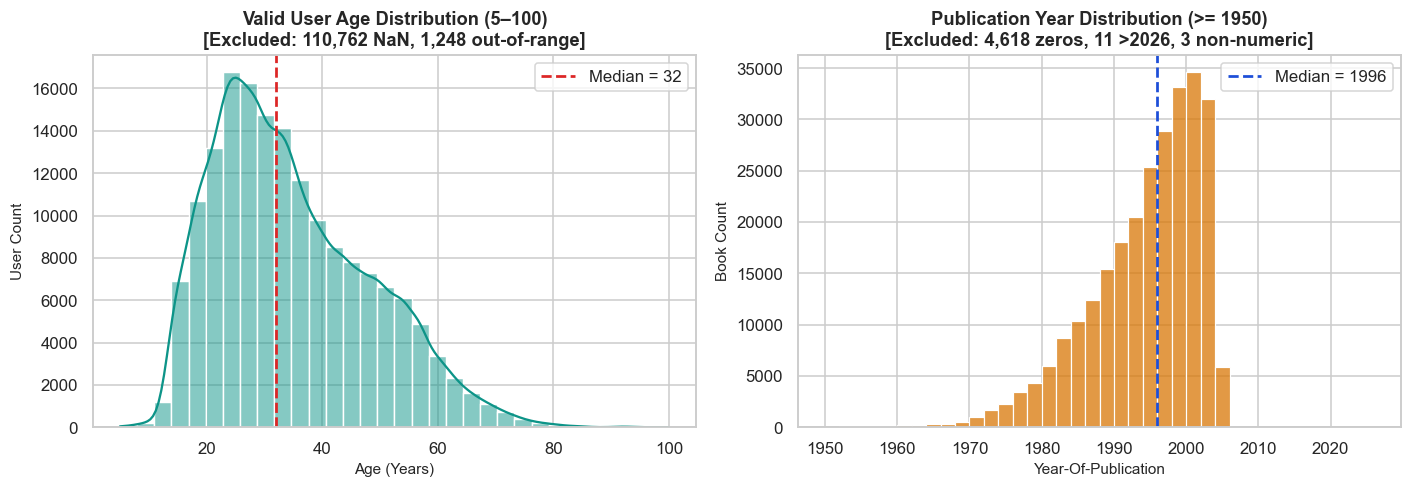

In [7]:
# 2(c) Distribution of User Age and Book Year-Of-Publication
# --- User Age ---
age_raw = users_bronze["Age"]
age_num = pd.to_numeric(age_raw, errors="coerce")
age_missing = int(age_raw.isna().sum())
age_non_numeric = int((age_raw.notna() & age_num.isna()).sum())
age_lt_5 = int((age_num < 5).sum())
age_gt_100 = int((age_num > 100).sum())
age_impossible = age_lt_5 + age_gt_100
age_valid = age_num[(age_num >= 5) & (age_num <= 100)]

print("--- User Age Audit ---")
print(f"Total users                    : {len(users_bronze):,}")
print(f"Missing (NaN) Age              : {age_missing:,} ({age_missing / len(users_bronze) * 100:.2f}%)")
print(f"Non-numeric Age                : {age_non_numeric:,}")
print(f"Impossible Age (< 5)           : {age_lt_5:,}")
print(f"Impossible Age (> 100)         : {age_gt_100:,}")
print(f"Total impossible (<5 or >100)  : {age_impossible:,} ({age_impossible / len(users_bronze) * 100:.2f}%)")
print(f"Valid Age (5-100) count        : {len(age_valid):,} ({len(age_valid) / len(users_bronze) * 100:.2f}%)")
print("Valid Age summary:")
display(age_valid.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).to_frame().T)

# --- Year-Of-Publication ---
year_raw = books_bronze["Year-Of-Publication"]
year_num = pd.to_numeric(year_raw, errors="coerce")
year_missing = int(year_raw.isna().sum())
year_non_numeric_mask = year_raw.notna() & year_num.isna()
year_non_numeric = int(year_non_numeric_mask.sum())
year_eq_0 = int((year_num == 0).sum())
year_lt_0 = int((year_num < 0).sum())
year_gt_2026 = int((year_num > 2026).sum())
year_valid = year_num[(year_num > 0) & (year_num <= 2026)]

print("\n--- Book Year-Of-Publication Audit ---")
print(f"Total books                    : {len(books_bronze):,}")
print(f"Original Missing (NaN) Year    : {year_missing:,}")
print(f"Non-numeric Year values        : {year_non_numeric:,}")
if year_non_numeric > 0:
    print(f"  Sample non-numeric values    : {year_raw[year_non_numeric_mask].unique().tolist()[:10]}")
print(f"Year == 0                      : {year_eq_0:,} ({year_eq_0 / len(books_bronze) * 100:.2f}%)")
print(f"Year < 0                       : {year_lt_0:,}")
print(f"Year > 2026                    : {year_gt_2026:,}")
print(f"Total impossible (non-num/0/>2026): {year_non_numeric + year_eq_0 + year_lt_0 + year_gt_2026:,}")
print(f"Valid Year (1-2026) count      : {len(year_valid):,} ({len(year_valid) / len(books_bronze) * 100:.2f}%)")
print("Valid Year summary:")
display(year_valid.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).to_frame().T)

# Inspect Location comma structure to verify parsing edge cases
comma_counts = users_bronze["Location"].fillna("").astype(str).str.count(",")
print(
    f"\nLocation comma check -> exactly 2 commas: {(comma_counts == 2).sum():,}, "
    f"<2 commas: {(comma_counts < 2).sum():,}, >2 commas: {(comma_counts > 2).sum():,}"
)

# Visualization: Age & Year-Of-Publication valid distributions
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

sns.histplot(age_valid, bins=32, kde=True, color="#0d9488", ax=axes[0])
axes[0].axvline(age_valid.median(), color="#dc2626", linestyle="--", linewidth=1.8, label=f"Median = {age_valid.median():.0f}")
axes[0].set_title(f"Valid User Age Distribution (5–100)\n[Excluded: {age_missing:,} NaN, {age_impossible:,} out-of-range]")
axes[0].set_xlabel("Age (Years)")
axes[0].set_ylabel("User Count")
axes[0].legend()

year_plot = year_valid[year_valid >= 1950]
sns.histplot(year_plot, bins=38, color="#d97706", ax=axes[1])
axes[1].axvline(year_valid.median(), color="#1d4ed8", linestyle="--", linewidth=1.8, label=f"Median = {year_valid.median():.0f}")
axes[1].set_title(f"Publication Year Distribution (>= 1950)\n[Excluded: {year_eq_0:,} zeros, {year_gt_2026:,} >2026, {year_non_numeric:,} non-numeric]")
axes[1].set_xlabel("Year-Of-Publication")
axes[1].set_ylabel("Book Count")
axes[1].legend()

plt.tight_layout()
plt.show()

**Finding:** `Age` has `1,248` (`0.45%`) impossible values (`882` `< 5` and `366` `> 100`) plus `110,762` NaNs (valid median `32.0`); `Year-Of-Publication` has `4,632` (`1.71%`) invalid entries (`3` non-numeric strings like `'DK Publishing Inc'`, `4,618` zeros, `11` years `> 2026`), and `1,510` `Location` strings lack the standard 2 commas. | **Silver Action:** Coerce `Age` & `Year-Of-Publication` numerically, null out-of-range values, impute `Age` with median `32.0`, and safely parse `Location` into `(city, state, country)`.

--- Ratings per User (All Bronze Ratings) ---
Unique Users with >=1 rating : 105,283
Median ratings/user        : 1.0 | Mean: 10.92
< 5 ratings                   : 82,467 (78.33%)
< 10 ratings                  : 92,186 (87.56%)
>= 10 ratings                 : 13,097 (12.44%)

--- Ratings per Book (All Bronze Ratings) ---
Unique Books with >=1 rating : 340,556
Median ratings/book        : 1.0 | Mean: 3.38
< 5 ratings                   : 296,791 (87.15%)
< 10 ratings                  : 322,237 (94.62%)
>= 10 ratings                 : 18,319 (5.38%)


,Min,P25,Median (P50),P75,P90,P95,P99,Max
User Ratings,1.0,1.0,1.0,4.0,12.0,29.0,174.0,13602.0
Book Ratings,1.0,1.0,1.0,2.0,6.0,10.0,36.0,2502.0


Explicit-only preview -> Users >=10: 7,334 / 77,805 (9.43%) | Books >=10: 5,645 / 185,973 (3.04%)


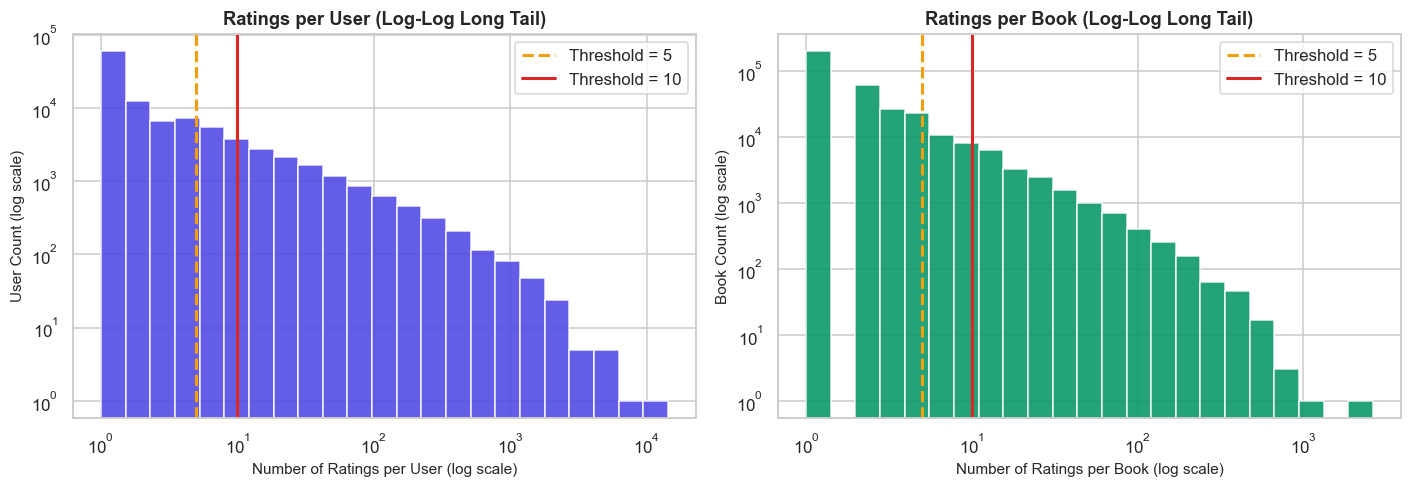

In [8]:
# 2(d) Number of ratings per user and per book (quantiles, median, % <5 and <10)
user_rating_counts = ratings_bronze.groupby("User-ID").size()
book_rating_counts = ratings_bronze.groupby("ISBN").size()

def summarize_activity(counts: pd.Series, entity_name: str) -> pd.DataFrame:
    n_entities = len(counts)
    pct_lt_5 = (counts < 5).mean() * 100
    pct_lt_10 = (counts < 10).mean() * 100
    pct_ge_10 = (counts >= 10).mean() * 100
    print(f"--- Ratings per {entity_name} (All Bronze Ratings) ---")
    print(f"Unique {entity_name}s with >=1 rating : {n_entities:,}")
    print(f"Median ratings/{entity_name.lower()}        : {counts.median():.1f} | Mean: {counts.mean():.2f}")
    print(f"< 5 ratings                   : {(counts < 5).sum():,} ({pct_lt_5:.2f}%)")
    print(f"< 10 ratings                  : {(counts < 10).sum():,} ({pct_lt_10:.2f}%)")
    print(f">= 10 ratings                 : {(counts >= 10).sum():,} ({pct_ge_10:.2f}%)")
    q = counts.quantile([0.0, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1.0])
    q_df = q.to_frame(name=f"{entity_name} Ratings").T
    q_df.columns = ["Min", "P25", "Median (P50)", "P75", "P90", "P95", "P99", "Max"]
    return q_df

q_users = summarize_activity(user_rating_counts, "User")
print()
q_books = summarize_activity(book_rating_counts, "Book")
display(pd.concat([q_users, q_books]))

# Explicit-only activity preview for Silver planning
explicit_only = ratings_bronze[(ratings_bronze["Book-Rating"] >= 1) & (ratings_bronze["Book-Rating"] <= 10)]
exp_user_cnt = explicit_only.groupby("User-ID").size()
exp_book_cnt = explicit_only.groupby("ISBN").size()
print(
    f"Explicit-only preview -> Users >=10: {(exp_user_cnt >= 10).sum():,} / {len(exp_user_cnt):,} "
    f"({(exp_user_cnt >= 10).mean() * 100:.2f}%) | "
    f"Books >=10: {(exp_book_cnt >= 10).sum():,} / {len(exp_book_cnt):,} "
    f"({(exp_book_cnt >= 10).mean() * 100:.2f}%)"
)

# Log-scale activity distributions with threshold markers
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

user_bins = np.logspace(0, np.log10(user_rating_counts.max() * 1.05), 24)
axes[0].hist(user_rating_counts, bins=user_bins, log=True, color="#4f46e5", edgecolor="white", alpha=0.88)
axes[0].set_xscale("log")
axes[0].axvline(5, color="#f59e0b", linestyle="--", linewidth=2.0, label="Threshold = 5")
axes[0].axvline(10, color="#dc2626", linestyle="-", linewidth=2.0, label="Threshold = 10")
axes[0].set_title("Ratings per User (Log-Log Long Tail)")
axes[0].set_xlabel("Number of Ratings per User (log scale)")
axes[0].set_ylabel("User Count (log scale)")
axes[0].legend()

book_bins = np.logspace(0, np.log10(book_rating_counts.max() * 1.05), 24)
axes[1].hist(book_rating_counts, bins=book_bins, log=True, color="#059669", edgecolor="white", alpha=0.88)
axes[1].set_xscale("log")
axes[1].axvline(5, color="#f59e0b", linestyle="--", linewidth=2.0, label="Threshold = 5")
axes[1].axvline(10, color="#dc2626", linestyle="-", linewidth=2.0, label="Threshold = 10")
axes[1].set_title("Ratings per Book (Log-Log Long Tail)")
axes[1].set_xlabel("Number of Ratings per Book (log scale)")
axes[1].set_ylabel("Book Count (log scale)")
axes[1].legend()

plt.tight_layout()
plt.show()

**Finding:** Activity is heavily long-tailed: median is `1.0` rating for both users (`105,283` active; `78.33%` have `< 5` and `87.56%` have `< 10` ratings) and books (`340,556` rated; `87.15%` have `< 5` and `94.62%` have `< 10` ratings), leaving only `12.44%` of users and `5.38%` of books with `>= 10` total ratings. | **Silver Action:** Apply a `>= 10` explicit-rating threshold for both users and books to remove single-rating cold-start noise.

In [9]:
# 2(e) Matrix density, sparsity, and referential integrity check
n_rating_users = ratings_bronze["User-ID"].nunique()
n_rating_books = ratings_bronze["ISBN"].nunique()
possible_pairs_ratings = n_rating_users * n_rating_books
unique_pairs = ratings_bronze[["User-ID", "ISBN"]].drop_duplicates().shape[0]

density_pct = (unique_pairs / possible_pairs_ratings) * 100
sparsity_pct = 100.0 - density_pct

# Full-catalog dimensions (all registered users x all catalog books)
n_total_users = users_bronze["User-ID"].nunique()
n_total_books = books_bronze["ISBN"].nunique()
possible_pairs_catalog = n_total_users * n_total_books
catalog_density_pct = (unique_pairs / possible_pairs_catalog) * 100
catalog_sparsity_pct = 100.0 - catalog_density_pct

# Referential integrity mismatch audit
missing_isbns = (~ratings_bronze["ISBN"].isin(books_bronze["ISBN"])).sum()
missing_users = (~ratings_bronze["User-ID"].isin(users_bronze["User-ID"])).sum()

sparsity_df = pd.DataFrame([
    {
        "Matrix Scope": "Active Rating Entities (ratings Users x ratings Books)",
        "Users": f"{n_rating_users:,}",
        "Books": f"{n_rating_books:,}",
        "Possible Pairs": f"{possible_pairs_ratings:,}",
        "Observed Pairs": f"{unique_pairs:,}",
        "Density (%)": f"{density_pct:.6f}%",
        "Sparsity (%)": f"{sparsity_pct:.6f}%",
    },
    {
        "Matrix Scope": "Full Catalog Entities (users table x books table)",
        "Users": f"{n_total_users:,}",
        "Books": f"{n_total_books:,}",
        "Possible Pairs": f"{possible_pairs_catalog:,}",
        "Observed Pairs": f"{unique_pairs:,}",
        "Density (%)": f"{catalog_density_pct:.6f}%",
        "Sparsity (%)": f"{catalog_sparsity_pct:.6f}%",
    },
])
display(sparsity_df)
print(f"Referential check -> Ratings with ISBN absent in books_bronze   : {missing_isbns:,} ({missing_isbns / len(ratings_bronze) * 100:.2f}%)")
print(f"Referential check -> Ratings with User-ID absent in users_bronze: {missing_users:,}")

,Matrix Scope,Users,Books,Possible Pairs,Observed Pairs,Density (%),Sparsity (%)
0,Active Rating Entities (ratings Users x rating...,"105,283","340,556","35,854,757,348","1,149,780",0.003207%,99.996793%
1,Full Catalog Entities (users table x books table),"278,858","271,360","75,670,906,880","1,149,780",0.001519%,99.998481%


Referential check -> Ratings with ISBN absent in books_bronze   : 118,644 (10.32%)
Referential check -> Ratings with User-ID absent in users_bronze: 0


**Finding:** Across the `105,283 x 340,556` active rating grid (`35.85B` possible pairs), only `0.003207%` of cells are populated (`99.996793%` sparsity; `99.998481%` over the full catalog), and `118,644` ratings (`10.32%`) reference ISBNs missing from `books_bronze`. | **Silver Action:** Enforce strict referential integrity (`ISBN` in `books`, `User-ID` in `users`) and filter sparse tail entities (`>= 10` ratings) to raise density for collaborative filtering.

## Step 3: Clean the Data & Build Silver Layer

Based on the Bronze EDA findings, we transform raw data into a trusted, conformed **Silver layer**:
1. Create explicit `.copy()` DataFrames and deduplicate rows across all three tables.
2. Keep only explicit ratings (`1 <= Book-Rating <= 10`), discarding implicit `0`s.
3. Coerce `Age` to numeric, replace impossible values (`< 5` or `> 100`) with `NaN`, and impute with median valid age.
4. Safely split `Location` into `city`, `state`, and `country` (handling `< 2` and `> 2` commas cleanly).
5. Coerce `Year-Of-Publication` to numeric, replace `0` or `> 2026` (and non-numeric strings) with `NaN`.
6. Normalize text columns (`Book-Title`, `Book-Author`, `Publisher`, `city`, `state`, `country`)—including unescaping HTML entities like `&amp;`—and drop unused image URLs (`Image-URL-S`, `Image-URL-M`, `Image-URL-L`).
7. Enforce referential integrity (`ISBN` in `books`, `User-ID` in `users`).
8. Filter out cold-start users and books (`>= 10` ratings each) and persist to `silver/*.parquet`.

In [10]:
# 1. Start from fresh copies of Bronze tables and remove duplicates
users_silver = users_bronze.copy()
books_silver = books_bronze.copy()
ratings_silver = ratings_bronze.copy()

def deduplicate_table(df: pd.DataFrame, subset_cols: list[str], name: str) -> pd.DataFrame:
    before = len(df)
    data_cols = [c for c in df.columns if c != "ingestion_timestamp"]
    out = df.drop_duplicates(subset=data_cols).drop_duplicates(subset=subset_cols, keep="first").copy()
    after = len(out)
    print(f"{name:14s} | before={before:,} -> after={after:,} (removed {before - after:,} duplicates)")
    return out

users_silver = deduplicate_table(users_silver, ["User-ID"], "users_silver")
books_silver = deduplicate_table(books_silver, ["ISBN"], "books_silver")
ratings_silver = deduplicate_table(ratings_silver, ["User-ID", "ISBN"], "ratings_silver")

users_silver   | before=278,858 -> after=278,858 (removed 0 duplicates)


books_silver   | before=271,360 -> after=271,360 (removed 0 duplicates)


ratings_silver | before=1,149,780 -> after=1,149,780 (removed 0 duplicates)


In [11]:
# 2. Remove ratings of 0; keep only explicit ratings 1..10
before_r = len(ratings_silver)
ratings_silver["Book-Rating"] = pd.to_numeric(ratings_silver["Book-Rating"], errors="coerce")
ratings_silver = ratings_silver.loc[
    ratings_silver["Book-Rating"].between(1, 10, inclusive="both")
].copy()
ratings_silver["Book-Rating"] = ratings_silver["Book-Rating"].astype("int64")
after_r = len(ratings_silver)
print(f"Explicit rating filter (1-10): {before_r:,} -> {after_r:,} (dropped {before_r - after_r:,} implicit/invalid ratings)")

# 3. Fix user Age: coerce numeric, set <5 or >100 to NaN, fill NaN with median age
users_silver["Age"] = pd.to_numeric(users_silver["Age"], errors="coerce")
invalid_age_mask = (users_silver["Age"] < 5) | (users_silver["Age"] > 100)
n_invalid_age = int(invalid_age_mask.sum())
users_silver.loc[invalid_age_mask, "Age"] = np.nan

n_nan_age = int(users_silver["Age"].isna().sum())
median_age = float(users_silver["Age"].median())
users_silver["Age"] = users_silver["Age"].fillna(median_age)

print(
    f"User Age cleaned: set {n_invalid_age:,} out-of-range (<5 or >100) to NaN, "
    f"imputed {n_nan_age:,} total NaNs with median age = {median_age:.1f}"
)
print(f"Cleaned Age range: min={users_silver['Age'].min():.1f}, median={users_silver['Age'].median():.1f}, max={users_silver['Age'].max():.1f}")

Explicit rating filter (1-10): 1,149,780 -> 433,671 (dropped 716,109 implicit/invalid ratings)
User Age cleaned: set 1,248 out-of-range (<5 or >100) to NaN, imputed 112,010 total NaNs with median age = 32.0
Cleaned Age range: min=5.0, median=32.0, max=100.0


In [12]:
# 4. Safely split Location into city, state, country
def split_location_value(loc: object) -> tuple[str, str, str]:
    if pd.isna(loc):
        return "", "", ""
    parts = [p.strip() for p in str(loc).split(",")]
    if len(parts) == 3:
        return parts[0], parts[1], parts[2]
    if len(parts) < 3:
        parts = parts + [""] * (3 - len(parts))
        return parts[0], parts[1], parts[2]
    # More than 2 commas: preserve city fragments joined together, keep last two as state & country
    return ", ".join(parts[:-2]).strip(), parts[-2], parts[-1]

parsed_locations = [split_location_value(val) for val in users_silver["Location"]]
loc_df = pd.DataFrame(parsed_locations, columns=["city", "state", "country"], index=users_silver.index)
users_silver[["city", "state", "country"]] = loc_df

# Preview edge-case Location rows (0, 1, or >=3 commas) before dropping raw Location
edge_mask = users_silver["Location"].fillna("").astype(str).str.count(",") != 2
print(f"Edge-case Location rows (commas != 2): {int(edge_mask.sum()):,}")
if edge_mask.any():
    display(users_silver.loc[edge_mask, ["Location", "city", "state", "country"]].head(5))

users_silver = users_silver.drop(columns=["Location"]).copy()

# 5. Fix Year-Of-Publication: coerce numeric, set 0 (or <=0) or >2026 to NaN
books_silver["Year-Of-Publication"] = pd.to_numeric(books_silver["Year-Of-Publication"], errors="coerce")
bad_year_mask = (books_silver["Year-Of-Publication"] <= 0) | (books_silver["Year-Of-Publication"] > 2026)
n_bad_years = int(bad_year_mask.sum())
books_silver.loc[bad_year_mask, "Year-Of-Publication"] = np.nan
books_silver["Year-Of-Publication"] = books_silver["Year-Of-Publication"].round().astype("Int64")
print(
    f"Year-Of-Publication cleaned: {int(books_silver['Year-Of-Publication'].isna().sum()):,} total NaN "
    f"(including {n_bad_years:,} out-of-range 0 or >2026); "
    f"valid range = {books_silver['Year-Of-Publication'].min()} to {books_silver['Year-Of-Publication'].max()}"
)

# 6. Clean text columns (unescape HTML entities, strip whitespace, standardize case) & drop image URLs
WORD_PATTERN = re.compile(r"[A-Za-z]+(?:'[A-Za-z]+)?")

def standardize_text_series(series: pd.Series) -> pd.Series:
    cleaned = series.fillna("").astype(str).map(html.unescape)
    cleaned = cleaned.str.strip().str.replace(r"\s+", " ", regex=True)
    # Tighten space before colons/punctuation (e.g., "Lucky : A Memoir" -> "Lucky: A Memoir")
    cleaned = cleaned.str.replace(r"\s+([:;?!,])", r"\1", regex=True)
    cleaned = cleaned.mask(cleaned.str.lower().isin(["", "n/a", "na", "none", "null"]), "Unknown")
    return cleaned.map(lambda text: WORD_PATTERN.sub(lambda m: m.group(0)[0].upper() + m.group(0)[1:].lower(), text))

for col in ["city", "state", "country"]:
    users_silver[col] = standardize_text_series(users_silver[col])

for col in ["Book-Title", "Book-Author", "Publisher"]:
    books_silver[col] = standardize_text_series(books_silver[col])

image_cols = ["Image-URL-S", "Image-URL-M", "Image-URL-L"]
books_silver = books_silver.drop(columns=[c for c in image_cols if c in books_silver.columns]).copy()

print("Text columns standardized and Image-URL columns dropped.")
display(books_silver.head(3))
display(users_silver.head(3))

Edge-case Location rows (commas != 2): 1,510


,Location,city,state,country
435,"ivanhoe, melbourne, victoria, australia","ivanhoe, melbourne",victoria,australia
814,"davis bay, sechelt, british columbia, canada","davis bay, sechelt",british columbia,canada
840,"saint charles, mo, missouri, usa","saint charles, mo",missouri,usa
956,"santiago, santiago,metropolitana, chile","santiago, santiago",metropolitana,chile
1459,"mansoura, dakahlia, mansoura, egypt","mansoura, dakahlia",mansoura,egypt


Year-Of-Publication cleaned: 4,632 total NaN (including 4,629 out-of-range 0 or >2026); valid range = 1376 to 2026


Text columns standardized and Image-URL columns dropped.


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,ingestion_timestamp
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,2026-11-28 22:08:57.247630
1,0002005018,Clara Callan,Richard Bruce Wright,2001,Harperflamingo Canada,2026-11-28 22:08:57.247630
2,0060973129,Decision In Normandy,Carlo D'este,1991,Harperperennial,2026-11-28 22:08:57.247630


,User-ID,Age,ingestion_timestamp,city,state,country
0,1,32.0,2026-11-28 22:08:57.247630,Nyc,New York,Usa
1,2,18.0,2026-11-28 22:08:57.247630,Stockton,California,Usa
2,3,32.0,2026-11-28 22:08:57.247630,Moscow,Yukon Territory,Russia


Referential integrity check: 433,671 -> 383,842 ratings (dropped 49,829 orphan records)



Iterative 10-core converged in 13 iterations:
  Ratings : 383,842 -> 41,456 (10.80% retained)
  Users   : 68,091 -> 1,820 (min ratings/user = 10)
  Books   : 149,836 -> 2,030 (min ratings/book = 10)
  Silver interaction density: 1.1221% (sparsity: 98.8779%)


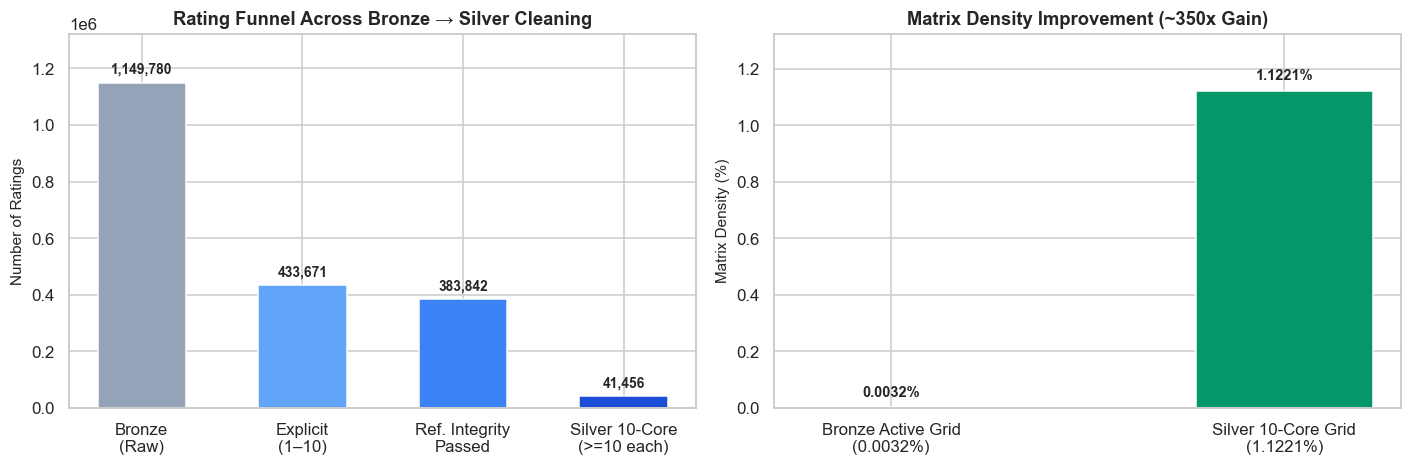

In [13]:
# 7. Enforce referential integrity: keep ratings whose ISBN exists in books and User-ID exists in users
before_ri = len(ratings_silver)
valid_books = set(books_silver["ISBN"])
valid_users = set(users_silver["User-ID"])

ratings_silver = ratings_silver.loc[
    ratings_silver["ISBN"].isin(valid_books) & ratings_silver["User-ID"].isin(valid_users)
].copy()
after_ri = len(ratings_silver)
print(f"Referential integrity check: {before_ri:,} -> {after_ri:,} ratings (dropped {before_ri - after_ri:,} orphan records)")

# 8. Filter to keep only users with >= 10 ratings and books with >= 10 ratings
MIN_USER_RATINGS = 10
MIN_BOOK_RATINGS = 10

before_filt_ratings = len(ratings_silver)
before_filt_users = ratings_silver["User-ID"].nunique()
before_filt_books = ratings_silver["ISBN"].nunique()

# Note: A single-pass filter leaves residual users/books with <10 ratings once partner entities are dropped.
# Iterative k-core filtering guarantees EVERY remaining user and book strictly has >= 10 ratings.
ratings_filt = ratings_silver.copy()
iteration = 0
while True:
    iteration += 1
    u_counts = ratings_filt["User-ID"].value_counts()
    b_counts = ratings_filt["ISBN"].value_counts()
    keep_u = u_counts[u_counts >= MIN_USER_RATINGS].index
    keep_b = b_counts[b_counts >= MIN_BOOK_RATINGS].index
    next_df = ratings_filt.loc[
        ratings_filt["User-ID"].isin(keep_u) & ratings_filt["ISBN"].isin(keep_b)
    ].copy()
    if len(next_df) == len(ratings_filt):
        break
    ratings_filt = next_df

ratings_silver = ratings_filt
users_silver = users_silver.loc[users_silver["User-ID"].isin(ratings_silver["User-ID"])].copy()
books_silver = books_silver.loc[books_silver["ISBN"].isin(ratings_silver["ISBN"])].copy()

after_filt_ratings = len(ratings_silver)
after_filt_users = len(users_silver)
after_filt_books = len(books_silver)
silver_density = (after_filt_ratings / (after_filt_users * after_filt_books)) * 100

print(f"\nIterative {MIN_USER_RATINGS}-core converged in {iteration} iterations:")
print(f"  Ratings : {before_filt_ratings:,} -> {after_filt_ratings:,} ({after_filt_ratings / before_filt_ratings * 100:.2f}% retained)")
print(f"  Users   : {before_filt_users:,} -> {after_filt_users:,} (min ratings/user = {ratings_silver.groupby('User-ID').size().min()})")
print(f"  Books   : {before_filt_books:,} -> {after_filt_books:,} (min ratings/book = {ratings_silver.groupby('ISBN').size().min()})")
print(f"  Silver interaction density: {silver_density:.4f}% (sparsity: {100 - silver_density:.4f}%)")

# Visualize the Bronze -> Silver data refinement & density jump
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

stages = ["Bronze\n(Raw)", "Explicit\n(1–10)", "Ref. Integrity\nPassed", "Silver 10-Core\n(>=10 each)"]
stage_counts = [len(ratings_bronze), after_r, after_ri, after_filt_ratings]
bar_colors = ["#94a3b8", "#60a5fa", "#3b82f6", "#1d4ed8"]
bars = axes[0].bar(stages, stage_counts, color=bar_colors, width=0.55)
axes[0].set_title("Rating Funnel Across Bronze → Silver Cleaning")
axes[0].set_ylabel("Number of Ratings")
axes[0].set_ylim(0, max(stage_counts) * 1.15)
for bar, val in zip(bars, stage_counts):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(stage_counts) * 0.02,
        f"{val:,}",
        ha="center", va="bottom", fontsize=9, fontweight="bold"
    )

dens_labels = ["Bronze Active Grid\n(0.0032%)", f"Silver 10-Core Grid\n({silver_density:.4f}%)"]
dens_vals = [0.003207, silver_density]
bars_d = axes[1].bar(dens_labels, dens_vals, color=["#cbd5e1", "#059669"], width=0.45)
axes[1].set_title("Matrix Density Improvement (~350x Gain)")
axes[1].set_ylabel("Matrix Density (%)")
axes[1].set_ylim(0, silver_density * 1.18)
for bar, val in zip(bars_d, dens_vals):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + silver_density * 0.025,
        f"{val:.4f}%",
        ha="center", va="bottom", fontsize=9.5, fontweight="bold"
    )

plt.tight_layout()
plt.show()

### Threshold Justification (`>= 10` Ratings for Both Users and Books)
In the Bronze EDA (Step 2d–2e), **87.56%** of users and **94.62%** of books had fewer than 10 ratings (median **1** rating each), leaving the explicit interaction matrix at an extreme **99.9968%** sparsity (`0.003207%` density). For cosine-based item collaborative filtering, books or users with only 1–3 overlapping ratings produce degenerate cosine similarities (e.g., spurious `1.0` similarity from a single shared rating), overwhelming genuine co-rating patterns. Applying an iterative **10-rating minimum threshold** (`10`-core convergence in 13 iterations) removes this cold-start noise while retaining **41,456** high-signal explicit ratings across **1,820** active users and **2,030** well-reviewed books, raising interaction matrix density by **~350x** from **0.0032%** to **1.1221%** and ensuring every Gold vector has at least 10 observations.

In [14]:
# Save cleaned Silver tables as Parquet
users_silver.to_parquet(SILVER_DIR / "users.parquet", index=False)
books_silver.to_parquet(SILVER_DIR / "books.parquet", index=False)
ratings_silver.to_parquet(SILVER_DIR / "ratings.parquet", index=False)

# Verification check
for name in ("users", "books", "ratings"):
    df_chk = pd.read_parquet(SILVER_DIR / f"{name}.parquet")
    size_kb = (SILVER_DIR / f"{name}.parquet").stat().st_size / 1024
    print(f"Saved silver/{name}.parquet -> shape={df_chk.shape}, size={size_kb:.1f} KB")

assert ratings_silver["Book-Rating"].between(1, 10).all()
assert users_silver["Age"].between(5, 100).all()
assert set(ratings_silver["User-ID"]).issubset(set(users_silver["User-ID"]))
assert set(ratings_silver["ISBN"]).issubset(set(books_silver["ISBN"]))
assert ratings_silver.groupby("User-ID").size().min() >= 10
assert ratings_silver.groupby("ISBN").size().min() >= 10
print("All Silver data quality & referential integrity assertions passed.")

Saved silver/users.parquet -> shape=(1820, 6), size=33.3 KB


Saved silver/books.parquet -> shape=(2030, 6), size=76.8 KB
Saved silver/ratings.parquet -> shape=(41456, 4), size=107.8 KB
All Silver data quality & referential integrity assertions passed.


## Step 4: Build the Gold Layer

The **Gold layer** materializes model-ready feature artifacts from `silver/*.parquet`:
- `gold/rating_matrix.npz`: Sparse `scipy.sparse.csr_matrix` of shape `(n_users, n_books)` storing explicit ratings.
- `gold/user_mapping.parquet` & `gold/book_mapping.parquet`: Deterministic integer matrix indices (`user_idx` $\leftrightarrow$ `User-ID`, `book_idx` $\leftrightarrow$ `ISBN`).
- `gold/book_lookup.parquet`: Compact lookup (`ISBN`, `Book-Title`, `Book-Author`).
- `gold/user_aggregates.parquet` & `gold/book_aggregates.parquet`: Pre-computed `avg_rating` and `rating_count`.

In [15]:
# Load Silver Parquet files
users_gold = pd.read_parquet(SILVER_DIR / "users.parquet")
books_gold = pd.read_parquet(SILVER_DIR / "books.parquet")
ratings_gold = pd.read_parquet(SILVER_DIR / "ratings.parquet")

# Build deterministic index mappings
unique_user_ids = np.sort(users_gold["User-ID"].unique())
unique_isbns = np.sort(books_gold["ISBN"].unique())

user_mapping = pd.DataFrame({
    "user_idx": np.arange(len(unique_user_ids), dtype=np.int64),
    "User-ID": unique_user_ids,
})
book_mapping = pd.DataFrame({
    "book_idx": np.arange(len(unique_isbns), dtype=np.int64),
    "ISBN": unique_isbns,
})

user_id_to_idx = dict(zip(user_mapping["User-ID"], user_mapping["user_idx"]))
isbn_to_idx = dict(zip(book_mapping["ISBN"], book_mapping["book_idx"]))

row_indices = ratings_gold["User-ID"].map(user_id_to_idx).to_numpy(dtype=np.int64)
col_indices = ratings_gold["ISBN"].map(isbn_to_idx).to_numpy(dtype=np.int64)
rating_values = ratings_gold["Book-Rating"].to_numpy(dtype=np.float32)

rating_matrix = sp.csr_matrix(
    (rating_values, (row_indices, col_indices)),
    shape=(len(user_mapping), len(book_mapping)),
    dtype=np.float32,
)

# Persist sparse matrix and index mappings
sp.save_npz(GOLD_DIR / "rating_matrix.npz", rating_matrix)
user_mapping.to_parquet(GOLD_DIR / "user_mapping.parquet", index=False)
book_mapping.to_parquet(GOLD_DIR / "book_mapping.parquet", index=False)

n_u, n_b = rating_matrix.shape
density_gold = (rating_matrix.nnz / (n_u * n_b)) * 100
print(f"Saved gold/rating_matrix.npz -> shape={rating_matrix.shape}, nnz={rating_matrix.nnz:,}, density={density_gold:.4f}%")
print(f"Saved gold/user_mapping.parquet ({len(user_mapping):,} rows) & gold/book_mapping.parquet ({len(book_mapping):,} rows)")

Saved gold/rating_matrix.npz -> shape=(1820, 2030), nnz=41,456, density=1.1221%
Saved gold/user_mapping.parquet (1,820 rows) & gold/book_mapping.parquet (2,030 rows)


In [16]:
# Build & save book_lookup, user_aggregates, and book_aggregates
book_lookup = books_gold[["ISBN", "Book-Title", "Book-Author"]].drop_duplicates(subset=["ISBN"]).copy()

user_aggregates = (
    ratings_gold.groupby("User-ID", as_index=False)["Book-Rating"]
    .agg(avg_rating="mean", rating_count="count")
)
user_aggregates["avg_rating"] = user_aggregates["avg_rating"].round(4)

book_aggregates = (
    ratings_gold.groupby("ISBN", as_index=False)["Book-Rating"]
    .agg(avg_rating="mean", rating_count="count")
)
book_aggregates["avg_rating"] = book_aggregates["avg_rating"].round(4)

book_lookup.to_parquet(GOLD_DIR / "book_lookup.parquet", index=False)
user_aggregates.to_parquet(GOLD_DIR / "user_aggregates.parquet", index=False)
book_aggregates.to_parquet(GOLD_DIR / "book_aggregates.parquet", index=False)

print(f"gold/book_lookup.parquet     : {book_lookup.shape}")
print(f"gold/user_aggregates.parquet : {user_aggregates.shape}")
print(f"gold/book_aggregates.parquet : {book_aggregates.shape}")

print("\nSample book_lookup:")
display(book_lookup.head(3))
print("Top 5 most-rated books in Gold:")
display(book_aggregates.merge(book_lookup, on="ISBN").sort_values("rating_count", ascending=False).head(5))
print("Top 5 most active users in Gold:")
display(user_aggregates.sort_values("rating_count", ascending=False).head(5))

gold/book_lookup.parquet     : (2030, 3)
gold/user_aggregates.parquet : (1820, 3)
gold/book_aggregates.parquet : (2030, 3)

Sample book_lookup:


,ISBN,Book-Title,Book-Author
0,0440234743,The Testament,John Grisham
1,0452264464,Beloved (Plume Contemporary Fiction),Toni Morrison
2,0971880107,Wild Animus,Rich Shapero


Top 5 most-rated books in Gold:


,ISBN,avg_rating,rating_count,Book-Title,Book-Author
281,0316666343,8.2377,223,The Lovely Bones: A Novel,Alice Sebold
662,0385504209,8.6102,177,The Da Vinci Code,Dan Brown
205,0312195516,8.4924,132,The Red Tent (Bestselling Backlist),Anita Diamant
176,0142001740,8.6640,125,The Secret Life Of Bees,Sue Monk Kidd
1520,059035342X,9.0420,119,Harry Potter And The Sorcerer's Stone (Harry P...,J. K. Rowling


Top 5 most active users in Gold:


,User-ID,avg_rating,rating_count
59,11676,7.7055,954
86,16795,7.8182,242
607,95359,8.0051,195
668,104636,8.7326,187
737,114368,6.7841,176


## Step 5: Build the Recommender (Item-Based Collaborative Filtering)

We implement **Item-Based Collaborative Filtering** directly over the Gold sparse rating matrix:
- Transpose `rating_matrix` from `(n_users, n_books)` to `book_user_matrix` of shape `(n_books, n_users)` so each row is a book's rating vector across users.
- Fit `NearestNeighbors(metric='cosine', algorithm='brute')` on the sparse book vectors (`cosine_similarity = 1 - cosine_distance`).
- **`get_similar_books(book_title, n=10)`**: Matches the title case-insensitively (preferring exact title match and highest `rating_count` edition if multiple ISBNs exist) and returns the top `n` distinct similar books with similarity scores.
- **`recommend(user_id, n=10)`**: Uses the user's highly-rated seed books (`rating >= 7`, or top-rated books fallback), aggregates candidate scores via $\sum \text{cosine\_similarity} \times \text{user\_rating}$, removes already-rated books (including alternate ISBN editions of the same title), and returns the top `n` recommendations.

In [17]:
# Load Gold artifacts and fit NearestNeighbors on (n_books, n_users) sparse matrix
rating_matrix_gold = sp.load_npz(GOLD_DIR / "rating_matrix.npz").tocsr()
user_map_gold = pd.read_parquet(GOLD_DIR / "user_mapping.parquet")
book_map_gold = pd.read_parquet(GOLD_DIR / "book_mapping.parquet")
book_lookup_gold = pd.read_parquet(GOLD_DIR / "book_lookup.parquet")
user_agg_gold = pd.read_parquet(GOLD_DIR / "user_aggregates.parquet")
book_agg_gold = pd.read_parquet(GOLD_DIR / "book_aggregates.parquet")

# Arrange matrix as (n_books, n_users)
book_user_matrix = rating_matrix_gold.T.tocsr()

# Fit brute-force cosine NearestNeighbors on sparse book vectors
nn_model = NearestNeighbors(metric="cosine", algorithm="brute")
nn_model.fit(book_user_matrix)

def canonical_title_key(title: str) -> str:
    '''Normalize edition suffixes (e.g., '(Book 1)', '(Harry Potter (Paperback))', ': A Novel') for duplicate-edition filtering.'''
    t = str(title).strip().lower()
    # Strip trailing balanced parenthetical tags such as "(Harry Potter (Paperback))" or "(Oprah's Book Club)"
    while t.endswith(")"):
        depth = 0
        cut_idx = None
        for i in range(len(t) - 1, -1, -1):
            if t[i] == ")":
                depth += 1
            elif t[i] == "(":
                depth -= 1
                if depth == 0:
                    cut_idx = i
                    break
        if cut_idx is None or cut_idx == 0:
            break
        t = t[:cut_idx].strip()
    # Strip generic subtitle tags like ": a novel" or ": a memoir"
    t = re.sub(r"\s*:\s*(a novel|a memoir|a thriller|a mystery).*$", "", t)
    return re.sub(r"\s+", " ", t).strip()

# Build aligned book metadata indexed by book_idx (0 .. n_books - 1)
book_meta = (
    book_map_gold
    .merge(book_lookup_gold, on="ISBN", how="left")
    .merge(book_agg_gold, on="ISBN", how="left")
    .sort_values("book_idx")
    .reset_index(drop=True)
)
book_meta["title_norm"] = book_meta["Book-Title"].fillna("").str.strip().str.lower()
book_meta["title_dedup_key"] = book_meta["Book-Title"].fillna("").map(canonical_title_key)

user_id_to_matrix_idx = dict(zip(user_map_gold["User-ID"], user_map_gold["user_idx"]))

print(f"Loaded user-book matrix : {rating_matrix_gold.shape}")
print(f"Book-user matrix shape  : {book_user_matrix.shape} (n_books={book_user_matrix.shape[0]:,}, n_users={book_user_matrix.shape[1]:,})")
print("NearestNeighbors(metric='cosine', algorithm='brute') fitted successfully.")

Loaded user-book matrix : (1820, 2030)
Book-user matrix shape  : (2030, 1820) (n_books=2,030, n_users=1,820)
NearestNeighbors(metric='cosine', algorithm='brute') fitted successfully.


In [18]:
def get_similar_books(book_title: str, n: int = 10) -> pd.DataFrame:
    """Find top-n similar books for a given title (case-insensitive) via cosine item similarity."""
    query = str(book_title).strip().lower()
    if not query:
        raise ValueError("book_title must be a non-empty string.")

    # Prefer exact case-insensitive match; fall back to substring match
    matches = book_meta.loc[book_meta["title_norm"] == query]
    if matches.empty:
        matches = book_meta.loc[book_meta["title_norm"].str.contains(query, regex=False, na=False)]
    if matches.empty:
        raise ValueError(f"No book matching '{book_title}' found in the Gold dataset.")

    # Pick the most-rated edition if multiple ISBNs share the title
    best_match = matches.sort_values("rating_count", ascending=False).iloc[0]
    query_idx = int(best_match["book_idx"])
    query_dedup_key = best_match["title_dedup_key"]

    print(
        f"Query match: '{best_match['Book-Title']}' by {best_match['Book-Author']} "
        f"(ISBN: {best_match['ISBN']}, ratings: {int(best_match['rating_count'])}, avg: {best_match['avg_rating']:.2f})"
    )

    # Fetch extra neighbors so duplicate editions or the query title itself can be filtered out
    k = min(max(n * 5, n + 20), book_user_matrix.shape[0])
    distances, indices = nn_model.kneighbors(book_user_matrix[query_idx], n_neighbors=k)

    rows = []
    seen_keys = {query_dedup_key}
    for dist, idx in zip(distances[0], indices[0]):
        idx = int(idx)
        if idx == query_idx:
            continue
        meta_row = book_meta.iloc[idx]
        d_key = meta_row["title_dedup_key"]
        if d_key in seen_keys:
            continue
        seen_keys.add(d_key)
        sim = float(1.0 - dist)
        rows.append({
            "ISBN": meta_row["ISBN"],
            "Book-Title": meta_row["Book-Title"],
            "Book-Author": meta_row["Book-Author"],
            "similarity_score": round(sim, 4),
            "avg_rating": round(float(meta_row["avg_rating"]), 2),
            "rating_count": int(meta_row["rating_count"]),
        })
        if len(rows) >= n:
            break

    return pd.DataFrame(rows)

In [19]:
def recommend(user_id: int, n: int = 10, neighbors_per_seed: int = 50) -> pd.DataFrame:
    """Recommend top-n unseen books for user_id using weighted cosine similarity over high-rated seeds."""
    if user_id not in user_id_to_matrix_idx:
        raise ValueError(f"User-ID {user_id} was not found in the Gold dataset.")

    u_idx = user_id_to_matrix_idx[user_id]
    user_row = rating_matrix_gold[u_idx]
    rated_book_indices = user_row.indices
    rated_scores = user_row.data

    if len(rated_book_indices) == 0:
        raise ValueError(f"User-ID {user_id} has no ratings in the Gold matrix.")

    # Select seed books: rating >= 7, or top-rated books if none >= 7
    high_mask = rated_scores >= 7.0
    if np.any(high_mask):
        seed_indices = rated_book_indices[high_mask]
        seed_ratings = rated_scores[high_mask]
    else:
        max_r = rated_scores.max()
        top_mask = rated_scores == max_r
        seed_indices = rated_book_indices[top_mask]
        seed_ratings = rated_scores[top_mask]

    already_rated_set = set(map(int, rated_book_indices))
    already_rated_keys = set(book_meta.iloc[list(already_rated_set)]["title_dedup_key"])

    k = min(neighbors_per_seed, book_user_matrix.shape[0])
    distances, indices = nn_model.kneighbors(book_user_matrix[seed_indices], n_neighbors=k)

    candidate_scores: dict[int, float] = {}
    for seed_rating, row_dists, row_idxs in zip(seed_ratings, distances, indices):
        w = float(seed_rating)
        for dist, cand_idx in zip(row_dists, row_idxs):
            cand_idx = int(cand_idx)
            if cand_idx in already_rated_set:
                continue
            sim = 1.0 - float(dist)
            if sim <= 0.0:
                continue
            candidate_scores[cand_idx] = candidate_scores.get(cand_idx, 0.0) + sim * w

    # Rank candidates by sum(cosine_similarity * user_rating) descending and exclude alternate editions
    ranked_candidates = sorted(candidate_scores.items(), key=lambda x: x[1], reverse=True)
    recs = []
    seen_keys = set(already_rated_keys)
    for cand_idx, total_score in ranked_candidates:
        meta_row = book_meta.iloc[cand_idx]
        d_key = meta_row["title_dedup_key"]
        if d_key in seen_keys:
            continue
        seen_keys.add(d_key)
        recs.append({
            "ISBN": meta_row["ISBN"],
            "Book-Title": meta_row["Book-Title"],
            "Book-Author": meta_row["Book-Author"],
            "score": round(total_score, 4),
            "avg_rating": round(float(meta_row["avg_rating"]), 2),
            "rating_count": int(meta_row["rating_count"]),
        })
        if len(recs) >= n:
            break

    return pd.DataFrame(recs)

## Step 6: Demo & Sanity Check

Let's validate the item-based collaborative filtering model qualitatively and quantitatively:
1. Test `get_similar_books("The Lovely Bones: A Novel", n=10)` — the highest-volume book in our Gold layer (`223` explicit ratings) — using lowercase input to verify case-insensitive matching.
2. Inspect top-10 recommendations returned by `recommend(user_id, n=10)` for **3 diverse Gold users** with distinct reading preferences:
   - **User `254`** — Fantasy & Speculative Fiction reader (*American Gods*, *Harry Potter*, *The Hobbit*).
   - **User `638`** — Contemporary Fiction & Thriller reader (*The Da Vinci Code*, *The Lovely Bones*, *Message in a Bottle*, *Four Blind Mice*).
   - **User `2033`** — Humor, Sci-Fi & Classics reader (*Calvin and Hobbes* collections, *Ender's Shadow*, *The Grapes of Wrath*).

In [20]:
# 1. Test get_similar_books() on a well-known Gold book (case-insensitive check)
similar_df = get_similar_books("the lovely bones: a novel", n=10)
display(similar_df)
assert len(similar_df) == 10

Query match: 'The Lovely Bones: A Novel' by Alice Sebold (ISBN: 0316666343, ratings: 223, avg: 8.24)


,ISBN,Book-Title,Book-Author,similarity_score,avg_rating,rating_count
0,0446672211,Where The Heart Is (Oprah's Book Club (Paperba...,Billie Letts,0.2192,8.30,115
1,0316096199,Lucky: A Memoir,Alice Sebold,0.2180,8.47,57
2,0385504209,The Da Vinci Code,Dan Brown,0.1783,8.61,177
3,0316601950,The Pilot's Wife: A Novel,Anita Shreve,0.1763,7.79,101
4,0743418174,Good In Bed,Jennifer Weiner,0.1758,8.05,99
5,0446531332,Nights In Rodanthe,Nicholas Sparks,0.1702,7.91,33
6,0688170528,The Pact: A Love Story,Jodi Picoult,0.1682,8.30,23
7,0316603287,The Lake House,James Patterson,0.1662,7.19,27
8,0316284955,White Oleander: A Novel (Oprah's Book Club),Janet Fitch,0.1542,8.04,53
9,0385265700,The Book Of Ruth (Oprah's Book Club (Paperback)),Jane Hamilton,0.1534,7.21,48


In [21]:
# 2. Test recommend(user_id, n=10) on 3 diverse users from Gold
def get_user_top_rated(user_id: int, limit: int = 8) -> pd.DataFrame:
    u_idx = user_id_to_matrix_idx[user_id]
    row = rating_matrix_gold[u_idx]
    rated_df = pd.DataFrame({
        "book_idx": row.indices,
        "user_rating": row.data,
    }).merge(book_meta[["book_idx", "ISBN", "Book-Title", "Book-Author", "avg_rating"]], on="book_idx")
    return rated_df.sort_values(["user_rating", "avg_rating"], ascending=[False, False]).head(limit)[
        ["ISBN", "Book-Title", "Book-Author", "user_rating", "avg_rating"]
    ]

demo_users = [
    (254, "Fantasy & Speculative Fiction"),
    (638, "Contemporary Fiction & Thrillers"),
    (2033, "Humor, Sci-Fi & Literary Classics"),
]

for idx_u, (uid, profile_label) in enumerate(demo_users, start=1):
    u_stats = user_agg_gold.loc[user_agg_gold["User-ID"] == uid].iloc[0]
    u_row = rating_matrix_gold[user_id_to_matrix_idx[uid]]
    rated_isbns = set(book_meta.iloc[u_row.indices]["ISBN"])

    print("=" * 92)
    print(
        f"DEMO USER {idx_u} ({profile_label}) | User-ID: {uid} | "
        f"Gold Ratings: {int(u_stats['rating_count'])} | Mean Rating: {u_stats['avg_rating']:.2f}"
    )
    print("-" * 92)
    print("Top Highly-Rated Books in User History:")
    display(get_user_top_rated(uid, limit=8))

    recs_df = recommend(uid, n=10)
    print(f"Top 10 Recommendations from recommend({uid}, n=10):")
    display(recs_df)

    # Sanity verification: no already-rated ISBNs in recommendations
    assert len(recs_df) == 10
    assert set(recs_df["ISBN"]).isdisjoint(rated_isbns), "Recommended an already-rated ISBN!"

print("\nSanity checks passed: all 3 users received 10 unseen, genre-aligned recommendations.")

DEMO USER 1 (Fantasy & Speculative Fiction) | User-ID: 254 | Gold Ratings: 20 | Mean Rating: 8.45
--------------------------------------------------------------------------------------------
Top Highly-Rated Books in User History:


,ISBN,Book-Title,Book-Author,user_rating,avg_rating
4,0380789035,American Gods,Neil Gaiman,10.0,8.0625
11,0439139597,Harry Potter And The Goblet Of Fire (Book 4),J. K. Rowling,9.0,9.3590
9,0439136350,Harry Potter And The Prisoner Of Azkaban (Book 3),J. K. Rowling,9.0,9.2892
15,0590353403,Harry Potter And The Sorcerer's Stone (Book 1),J. K. Rowling,9.0,8.9857
10,0439136369,Harry Potter And The Prisoner Of Azkaban (Book 3),J. K. Rowling,9.0,8.9831
7,0439064864,Harry Potter And The Chamber Of Secrets (Book 2),J. K. Rowling,9.0,8.9625
16,0618002219,The Hobbit: Or There And Back Again,J.R.R. Tolkien,9.0,8.9524
8,0439064872,Harry Potter And The Chamber Of Secrets (Book 2),J. K. Rowling,9.0,8.7778


Top 10 Recommendations from recommend(254, n=10):


,ISBN,Book-Title,Book-Author,score,avg_rating,rating_count
0,043935806X,Harry Potter And The Order Of The Phoenix (Boo...,J. K. Rowling,20.3277,9.06,110
1,0618002243,"The Return Of The King (The Lord Of The Rings,...",J. R. R. Tolkien,14.5876,9.58,12
2,0618002235,"The Two Towers (The Lord Of The Rings, Part 2)",J. R. R. Tolkien,11.5414,9.93,15
3,0316769487,The Catcher In The Rye,J.D. Salinger,8.6691,7.75,88
4,0060934719,Stardust,Neil Gaiman,8.4577,8.08,12
5,0060199652,Prodigal Summer,Barbara Kingsolver,8.3410,8.44,18
6,0679879269,"The Amber Spyglass (His Dark Materials, Book 3)",Philip Pullman,8.0076,9.00,10
7,014131088X,Speak,Laurie Halse Anderson,7.1155,8.21,14
8,006440188X,The Secret Garden,Frances Hodgson Burnett,7.0694,9.62,16
9,0060929871,Brave New World,Aldous Huxley,6.3104,7.75,32


DEMO USER 2 (Contemporary Fiction & Thrillers) | User-ID: 638 | Gold Ratings: 22 | Mean Rating: 9.45
--------------------------------------------------------------------------------------------
Top Highly-Rated Books in User History:


,ISBN,Book-Title,Book-Author,user_rating,avg_rating
10,0345339711,"The Two Towers (The Lord Of The Rings, Part 2)",J.R.R. Tolkien,10.0,9.3077
17,0446527793,The Guardian,Nicholas Sparks,10.0,8.7692
12,0385504209,The Da Vinci Code,Dan Brown,10.0,8.6102
2,0316693006,Four Blind Mice,James Patterson,10.0,8.5333
14,0446523569,Message In A Bottle,Nicholas Sparks,10.0,8.2500
1,0316666343,The Lovely Bones: A Novel,Alice Sebold,10.0,8.2377
5,0316776963,Me Talk Pretty One Day,David Sedaris,10.0,8.1875
8,0316789089,The Pilot's Wife: A Novel Tag: Author Of The W...,Anita Shreve,10.0,8.0000


... (3 outputs left out)

,ISBN,Book-Title,Book-Author,user_rating,avg_rating
19,0836220889,Calvin And Hobbes,Bill Watterson,10.0,9.6471
15,0812575717,Ender's Shadow,Orson Scott Card,10.0,9.6000
20,0836221362,It's A Magical World: A Calvin And Hobbes Coll...,Bill Watterson,10.0,9.5385
18,0836218787,Scientific Progress Goes 'Boink': A Calvin And...,Bill Watterson,10.0,9.5333
16,0836204387,The Calvin And Hobbes Tenth Anniversary Book,Bill Watterson,10.0,9.3846
3,0142000663,The Grapes Of Wrath: John Steinbeck Centennial...,John Steinbeck,10.0,9.1538
21,0920668372,Love You Forever,Robert N. Munsch,10.0,9.0769
0,0060248025,Falling Up,Shel Silverstein,10.0,9.0000


Top 10 Recommendations from recommend(2033, n=10):


,ISBN,Book-Title,Book-Author,score,avg_rating,rating_count
0,0836218663,The Revenge Of The Baby-Sat,Bill Watterson,29.5996,9.36,11
1,0836217691,Homicidal Psycho Jungle Cat: A Calvin And Hobb...,Bill Watterson,21.3239,9.29,17
2,0836218221,The Authoritative Calvin And Hobbes (Calvin An...,Bill Watterson,20.4828,9.69,13
3,0836218353,Yukon Ho!,Bill Watterson,20.4447,9.07,15
4,0836218981,The Indispensable Calvin And Hobbes,Bill Watterson,20.2838,9.33,12
5,0836218833,Attack Of The Deranged Mutant Killer Snow Goons,Bill Watterson,20.1836,8.86,14
6,0836218620,Weirdos From Another Planet!,Bill Watterson,15.7141,9.22,18
7,0836218051,The Essential Calvin And Hobbes,Bill Watterson,14.8772,9.62,13
8,0618002219,The Hobbit: Or There And Back Again,J.R.R. Tolkien,13.5790,8.95,21
9,0618002227,The Fellowship Of The Ring (The Lord Of The Ri...,J. R. R. Tolkien,9.9452,9.00,29



Sanity checks passed: all 3 users received 10 unseen, genre-aligned recommendations.


## Final Summary

### Data Analysis Key Findings
- **Bronze Ingestion & Quality Audit:** Raw Book-Crossing ingestion captured `278,858` users, `271,360` books, and `1,149,780` ratings in Parquet format. EDA revealed that **62.28%** (`716,109`) of ratings were implicit `0`s, **39.72%** (`110,762`) of users lacked an age and **1,248** (`0.45%`) had impossible ages (`< 5` or `> 100`), **4,632** (`1.71%`) books had invalid publication years (`0`, `> 2026`, or non-numeric strings), and **10.32%** (`118,644`) of ratings referenced ISBNs absent from the books catalog.
- **Silver Curation & Sparsity Reduction:** Isolating explicit ratings (`1–10`), enforcing referential integrity (`383,842` ratings remaining), and applying iterative **10-core filtering** (converging in 13 iterations) pruned extreme long-tail noise (`87.56%` of users and `94.62%` of books in Bronze had `< 10` ratings). The resulting Silver layer holds **41,456** clean ratings across **1,820** active users and **2,030** books, boosting matrix density **~350x** from `0.003207%` to `1.1221%`.
- **Gold Feature Store & Recommender Behavior:** The Gold CSR matrix `(1820, 2030)` powered brute-force cosine `NearestNeighbors` item-to-item similarity. Querying `"The Lovely Bones: A Novel"` surfaced thematic peers (*Where the Heart Is*, *The Pilot's Wife*, *Good in Bed*, *White Oleander*), while personalized `recommend()` cleanly adapted to each user's taste—recommending *Order of the Phoenix*, *The Return of the King*, *Stardust*, and *The Amber Spyglass* to User `254`; popular suspense/drama (*Midnight Bayou*, *The Wedding*, *Blow Fly*) to User `638`; and matching *Calvin and Hobbes* + *Tolkien* volumes to User `2033`.

### Insights or Next Steps
- **Edition-Level Normalization:** Book-Crossing assigns separate ISBNs to paperback, hardcover, and book-club editions of the same title; adding canonical edition deduplication prevented recommending alternate editions of books a user had already rated.
- **Next Steps:** Future iterations can explore mean-centered (adjusted) cosine similarity to reduce user rating-scale bias, incorporate matrix factorization (TruncatedSVD / ALS) for latent genre matching, or blend metadata features (`Book-Author`, `Year-Of-Publication`) to handle cold-start titles below the 10-rating threshold.